# Etkileşimli Grafikler: plotly

Bu derste grafiklerimiz hareketleniyor. Şimdiye kadar ürettiğin grafikler **statikti**: ne görüyorsan oydu. plotly ile üretilen grafikler **etkileşimlidir**: noktaların üzerine gelince değer görünür, fareyle yakınlaştırma yapılır, göstergeden seriler açılıp kapanır. Ayrıca bu dersin gizli konusu: aynı grafiğin hangi ortamda nasıl görüneceğini bilmek ve ona göre üretmek.

## 🎯 Bu Derste Ne Öğreneceğiz?

Bu dersin sonunda şunları yapabileceksin:

- plotly express ile etkileşimli çizgi, çubuk ve dağılım grafikleri üretmek
- Hover, zoom, pan ve gösterge etkileşimlerini kullanmak
- `renderer` kavramını anlamak: aynı grafiğin etkileşimli ve statik sürümlerini üretmek
- Grafiği bağımsız HTML dosyası olarak kaydetmek
- Etkileşimli grafiğin hangi ortamda (Jupyter, Colab, GitHub) nasıl davranacağını bilmek

Bu ders, kursun 9. öğrenme çıktısının ilk yarısını karşılıyor.

## 💡 Neden Bu Konuyu Öğreniyoruz?

Statik grafik, sunumun ve raporun aracıdır: mesajı keskinleştirir, her yerde aynı görünür. Etkileşimli grafik ise **keşfin** aracıdır: "bu tepe hangi güne denk geliyor?", "bu aykırı nokta kim?" sorularını fareyle sormanın karşılığını anında alırsın. Veri analizi yapan herkes iki mod arasında gidip gelir.

İkinci neden ortam farkıdır: bu kursun defterleri GitHub'da da okunuyor ve GitHub, defterlerdeki JavaScript çıktılarını göstermez — yani etkileşimli grafiği GitHub'da gezen biri göremez. Bu yüzden bu derste her önemli grafiğin **etkileşimli ve statik** iki sürümünü üreteceğiz; hangi ortam hangi sürümü görüyor sorusunun cevabı sende olacak.

## 🔗 Ön Bilgi

- [Matplotlib Temelleri](07-Matplotlib-Basics.ipynb) ve [İleri Düzey](08-Matplotlib-Advanced.ipynb): grafik türleri, gösterge, çoklu seri.
- [Zaman Serileri Görselleştirme](11-Time-Series.ipynb): bu dersteki örnek veri (corona serisi) oradan geliyor.
- [pandas DataFrame](05-Pandas-Dataframe.ipynb): `groupby` ile veri hazırlama.

## 🔍 Birlikte Keşfedelim

Önce ortamı kuralım. plotly kurulu değilse `pip install plotly kaleido` ile kurabilirsin (Anaconda ortamında terminalden). Aşağıdaki hücre ayrıca varsayılan **renderer**'ı ayarlıyor; bunun ne demek olduğunu birazdan açıklayacağız:

In [1]:
import pandas as pd
import plotly.express as px
import plotly.io as pio

%matplotlib inline

pio.renderers.default = "notebook_connected"

corona = pd.read_csv("../Data/11-corona-data.csv")
corona["date"] = pd.to_datetime(corona["date"], format="%m/%d/%Y")

print("Hazır. Corona verisi:", corona.shape)

Hazır. Corona verisi: (112, 188)


Şimdi 11. dersteki Türkiye serisini plotly'la çizelim. Çalıştırdıktan sonra (kendi ortamında) grafiğin **üzerine gel**: imlecin durduğu noktanın tarihi ve değeri kutuda belirecek. Sonra tekerlekle yakınlaştır, sürükleyerek kaydır:

**Tahminin:** Aynı grafiği matplotlib ile çizmiştin. Bir noktanın tam değerini öğrenmek istesen statik grafikte ne yapardın, etkileşimli grafikte ne yapıyorsun? İki yöntemin maliyetini karşılaştır.

In [2]:
fig = px.line(corona, x="date", y="Turkey",
              title="Türkiye: Kümülatif Vaka (COVID-19, 2020)")
fig.update_layout(yaxis_title="Kümülatif vaka", xaxis_title="Tarih")
fig.show()

**Gözlem:** Statik grafikte değer okumak göz kararıydı: eksen çizgilerini takip eder, yanılırdın. Etkileşimli grafikte değer grafiğin kendisi söylüyor. Bedeli var mı? Evet: bu çıktı tarayıcıda çalışan koddur ve her ortamda görünmez — aşağıda bunu çözeceğiz.

Ama önce şunu netleştirelim: plotly'in grafik anlayışı tanıdık. `px.line` = çizgi grafiği, `x`/`y` = eksenler, `title` = başlık. seaborn'daki `data`/`x`/`y` arayüzünün aynısı; fark, çıktının canlı olması.

## 📖 Kavramlar

**plotly express (px):** plotly'in yüksek seviyeli arayüzü. `px.line`, `px.bar`, `px.scatter` gibi fonksiyonlar, DataFrame + sütun adlarıyla çalışır (seaborn gibi) ve etkileşimli grafik döndürür.

**Etkileşimler:** Hover (üzerine gelince değer kutusu), zoom (tekerlek ya da kutu seçimi), pan (sürükleme), gösterge tıklaması (seriyi aç/kapat). Bunlar grafikle birlikte otomatik gelir; kod yazmazsın.

**Renderer (görüntüleyici):** Grafiğin hangi biçimde görüntüleneceğine karar veren mekanizma. `fig.show()` varsayılan renderer'ı kullanır (biz `notebook_connected` ayarladık: küçük dosya, internetten plotly.js yükler). `fig.show(renderer="png")` grafiği **statik görüntüye** çevirir — GitHub'ın gösterdiği budur. Bu dersteki strateji: etkileşimli hücre + yanına statik kopya.

**HTML dışa aktarma:** `fig.write_html("grafik.html")` grafiği, tarayıcıda açılabilen bağımsız bir dosyaya yazar. Rapor eklerine ve paylaşım için kullanılır.

**Ortam farkları:** Jupyter/Colab → etkileşimli çıktı çalışır. GitHub defter önizlemesi → JavaScript çıktıları gösterilmez; statik (PNG) kopya gerekir. Statik rapor → yalnız statik sürüm anlamlıdır.

## 🛠️ Uygulama

### 1) Etkileşimli + statik kopya deseni

Yukarıdaki grafiğin GitHub'da da görünen statik kopyasını üretelim:

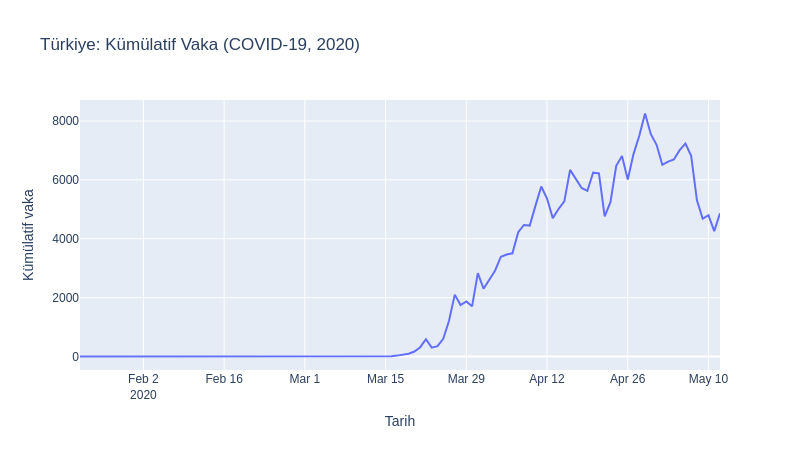

In [3]:
fig.show(renderer="png", width=800, height=450)

Aynı `fig` nesnesi, iki sunum. Bu iki satırlık desen (önce `fig.show()`, sonra `fig.show(renderer="png")`) bu dersteki standart kalıbımız olacak. `width`/`height` piksel cinsinden boyut verir.

### 2) Gösterge etkileşimi: serileri açıp kapatmak

In [4]:
ulkeler = corona[["date", "US", "Italy", "Germany", "Turkey"]]

fig = px.line(ulkeler, x="date", y=["US", "Italy", "Germany", "Turkey"],
              title="Kümülatif Vaka: Dört Ülke")
fig.update_layout(yaxis_title="Kümülatif vaka", xaxis_title="Tarih")
fig.show()

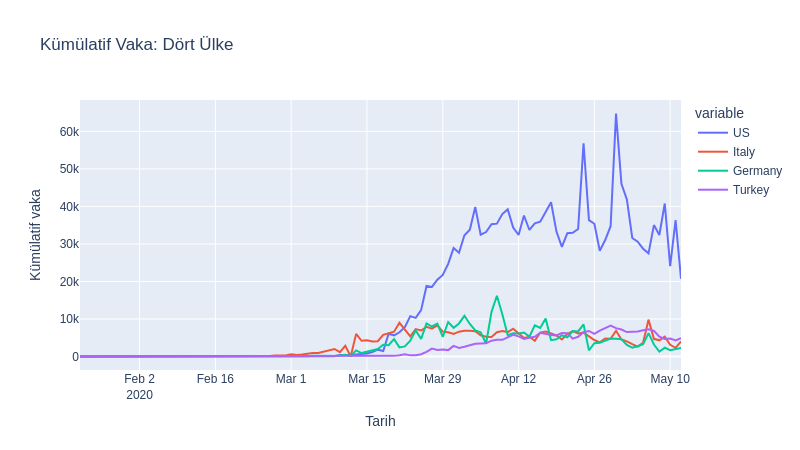

In [5]:
fig.show(renderer="png", width=800, height=450)

Bu grafiği kendi ortamında açtığında göstergedeki ülke adlarına **tıkla**: her tık o seriyi kapatıp açar. Dört seriden ikisini kapatıp kalan ikisini karşılaştırmak, statik grafikte "yeniden çiz" demekti; burada tek tık. ABD serisinin diğerlerini ezmeye başladığı yerde dikey eksenin ölçeğine dikkat: yakınlaştırıp alttaki üç ülkeyi izole etmeyi dene.

### 3) Çubuk grafik ve hover detayı

Kahve zinciri verisine dönelim; şehir toplamlarını etkileşimli çubuk grafikle gösterelim:

In [6]:
satis = pd.read_csv("../Data/05-coffee-sales.csv")
sehir_toplam = (satis.groupby("sehir")["adet"].sum()
                .reset_index()
                .sort_values("adet", ascending=False))

fig = px.bar(sehir_toplam, x="sehir", y="adet",
             title="Şehir Bazında Toplam Satış", color="sehir")
fig.update_layout(yaxis_title="Satış adedi", xaxis_title="Şehir",
                  showlegend=False)
fig.show()

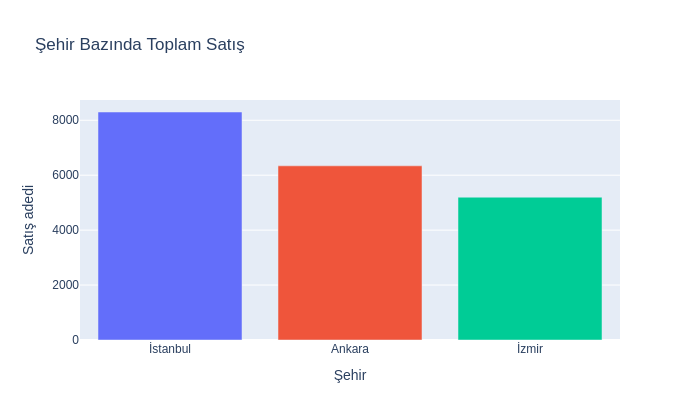

In [7]:
fig.show(renderer="png", width=700, height=420)

Çubukların üzerine gelince tam değer görünür — statik grafikte y ekseni okuyarak tahmin ettiğin bilgi. `color="sehir"` her çubuğa kendi rengini verdi; göstergeyi `showlegend=False` ile kapattık çünkü x ekseni zaten adları taşıyor (1. ders: tekrar etme).

### 4) Dağılım grafiği: renk, boyut ve hover verisi

10. dersteki öğrenci verisiyle: çalışma-not ilişkisi, bölüm renkleri, kahve tüketimi nokta boyutu ve hover'da tüm detaylar:

In [8]:
ogrenci = pd.read_csv("../Data/10-student-habits.csv")

fig = px.scatter(ogrenci, x="calisma_saati", y="vize_notu",
                 color="bolum", size="kahve_fincan",
                 hover_data=["uyku_saati", "sosyal_medya_saati"],
                 title="Çalışma ve Not İlişkisi (nokta boyutu: kahve)")
fig.update_layout(yaxis_title="Vize notu", xaxis_title="Haftalık çalışma saati")
fig.show()

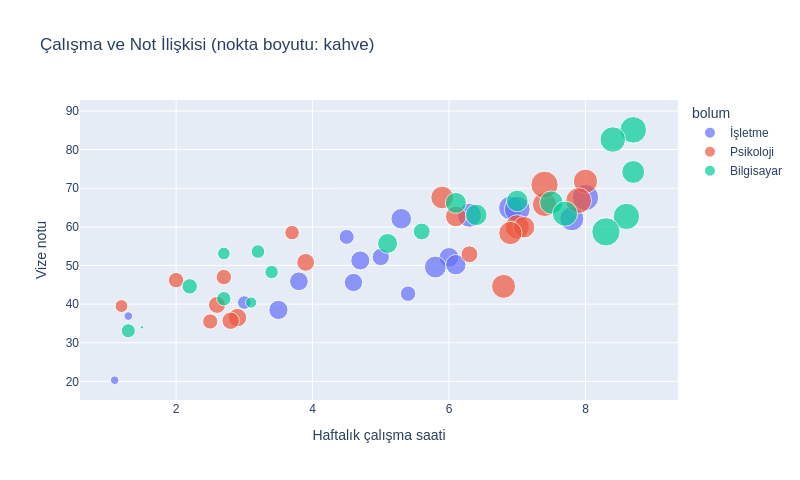

In [9]:
fig.show(renderer="png", width=800, height=480)

Tek grafikte dört değişken var: x, y, renk (bölüm) ve boyut (kahve). Üzerine gelince beşincisi (uyku, sosyal medya) da hover kutusunda. Bu yoğunluk etkileşimli grafikte çalışır çünkü detay **istendiğinde** gelir; statik grafikte aynı yoğunluk 1. dersin "kalabalık grafik" hatası olurdu.

### 5) HTML olarak kaydetmek

In [10]:
fig.write_html("calisma-not.html")
print("calisma-not.html kaydedildi.")

calisma-not.html kaydedildi.


Dosya defterin yanına yazıldı; çift tıklayınca tarayıcıda açılır ve tam etkileşimlidir. Böyle bir dosyayı raporuna ekleyebilir ya da arkadaşına gönderebilirsin. (Dosyanın boyutu birkaç yüz kilobayt olabilir; plotly.js kütüphanesi dosyaya gömülür.)

### 6) Kodu tamamla (TODO)

In [11]:
# TODO: Almanya'nın günlük yeni vaka serisini (diff + fillna(0))
# etkileşimli çizgi grafiğe dök ve statik kopyasını da üret.
# İpucu: Önce yeni bir sütun hesapla, sonra px.line'ı corona tablosuyla kullan.

# corona["Germany_gunluk"] = ...
# fig = px.line(...)
# fig.show()
# fig.show(renderer="png", width=800, height=450)

print("Kontrol: Almanya son gün toplam:", corona["Germany"].iloc[-1])

Kontrol: Almanya son gün toplam: 2255


Çözüm "Cevaplar" bölümünde.

## 🧪 Deneyelim ve Gözlemleyelim

Bu bölümdeki deneyler kendi ortamında yapılır; GitHub'da okuyorsan defteri indirip çalıştırman gerekir.

**Deney 1:** Dört ülkeli grafikte göstergeden "US" serisini kapat. Diğer üç serinin okunması nasıl değişti? Sonra çift tıkla (tüm seriler geri gelir). Bu "filtreleme" yeteneğinin statik grafikteki karşılığı nedir?

**Deney 2:** Türkiye serisinin üzerinde mart sonu ile nisan ortası arasına bir kutu çiz (yakınlaştırma). Eğimin değiştiği noktayı bul; hover ile o tarihin tam değerini oku. Statik grafikte aynı noktayı nasıl bulurdun?

**Deney 3:** Dağılım grafiğinde `size` parametresini kaldır (`size` ve `hover_data`'yı sil, yalnız `color` kalsın). Hangi bilgi kayboldu? Boyut eşlemesi neyi anlatıyordu? Sözlü yanıt yeterli; kararını 1. dersin ilkeleriyle gerekçelendir.

## 🧯 Bir Şeyler Ters Giderse

| Belirti | Olası neden | Çözüm |
|---|---|---|
| `ValueError: Image export using the kaleido engine requires the kaleido package` | kaleido kurulu değil | `pip install kaleido` |
| PNG üretiminde Chrome/browsers hatası | Yeni kaleido sürümü Chrome arıyor ve bulamıyor | Chrome kurulu değilse `pip install "kaleido==0.2.1"` ile eski (kendi motorunu taşıyan) sürümü kullan |
| Etkileşimli grafik boş görünüyor | Yanlış renderer ya da internet yok (notebook_connected CDN'e bağlanır) | `fig.show()`'u yeniden çalıştır; internet olmadan statik renderer kullan |
| Grafik GitHub'da görünmüyor | GitHub defterlerdeki JavaScript çıktılarını göstermez | Beklenen davranış; `fig.show(renderer="png")` ile statik kopya ekle |
| HTML dosyası çok büyük | plotly.js dosyaya gömülüyor | Normaldir (birkaç yüz KB); paylaşımda sorun değildir |
| VS Code'ta grafik farklı/eski görünüyor | VS Code, kendi plotly.js sürümünü kullanır | Genellikle görünür; ciddi uyuşmazlıkta tarayıcıdaki Jupyter'i dene |

> **İpucu:** plotly grafiklerinde de tasarım ilkeleri geçerli: hover detayı, kalabalık sütunların "gizleme" bahanesi değildir. Etkileşim, iyi tasarlanmış grafiği güçlendirir; kötü tasarımı kurtarmaz.

## 🏋️ Kendin Dene

1. **Zaman serisi keşfi:** İtalya'nın günlük vaka serisini etkileşimli çizgi grafiğe dök. Zoom ile zirve haftasını bul, hover ile zirve gününü ve değerini oku. Bulduklarını iki cümleyle not et.
2. **Kahve keşfi:** `satis` tablosundan şehir × ürün kırılımında ortalama adet içeren bir tablo kur ve `px.bar` ile çiz (`color="urun"`, `barmode="group"`). Gösterge tıklamalarıyla ürünleri tek tek incele.
3. **HTML raporu:** 2. görevdeki grafiği `kahve-raporu.html` olarak kaydet ve tarayıcıda aç. Etkileşimler dosyada da çalışıyor mu?

<details>
<summary>İpucu</summary>

Şehir × ürün ortalaması için: `satis.groupby(["sehir", "urun"])["adet"].mean().reset_index()`. `barmode="group"` yan yana çubuklar açar; `"stack"` üst üste dizer (2. dersin parça-bütün sorusu).

</details>

## 🧠 Öğrendiklerini Kontrol Et

Cevaplar defterin sonundaki "Cevaplar" bölümünde. Önce kendin dene.

1. Statik grafik ile etkileşimli grafiğin rollerini birer cümleyle ayırt et: hangisi rapor için, hangisi keşif için?
2. `fig.show()` ile `fig.show(renderer="png")` arasındaki fark nedir? Bu derste neden ikisini ardı ardına kullanıyoruz?
3. GitHub'da bu dersin defterini gezen biri, `fig.show()` hücresinin çıktısında ne görür? Neden?
4. `px.scatter`'daki `color`, `size` ve `hover_data` parametreleri sırasıyla hangi bilgileri grafiğe taşır?
5. `fig.write_html()` ne üretir, içindeki etkileşimler dosya açıldığında çalışır mı?
6. plotly express arayüzü hangi önceki dersin hangi arayüzüne benzer? Benzerlik nedir?

## 🚀 Bağımsız Çalışma

- **Galeri turu:** plotly express dokümantasyon galerisini (plotly.com/python/plotly-express/) gez; `px.scatter_matrix`, `px.sunburst`, `px.choropleth` gibi fonksiyonların örneklerini incele. Birini kendi verimizle dene.
- **Sınır araştırması:** "Etkileşimli grafik her zaman daha mı iyi?" sorusunu araştır: sunum, yazdırma ve hızlı tarama senaryolarında statik grafiğin avantajlarını listeleyip iki-üç cümlelik bir öneri yaz.

## 📚 Daha Fazlasını Öğrenmek

- plotly express: https://plotly.com/python/plotly-express/
- Renderer mekanizması: https://plotly.com/python/renderers/

İngilizcedir; kodlar doğrudan çalıştırılabilir.

## ✅ Kısa Özet

- plotly express, DataFrame + sütun adlarıyla etkileşimli grafik üretir; arayüzü seaborn'a benzer.
- Etkileşimler (hover, zoom, pan, gösterge tıklaması) ücretsiz gelir: keşif hızını artırır.
- Renderer kavramı sunumu belirler: `notebook_connected` küçük etkileşimli çıktı, `"png"` statik görüntü.
- GitHub defter önizlemesi JavaScript göstermez: her önemli grafiğin statik kopyasını ekle.
- `color`/`size`/`hover_data` ile tek grafiğe üç-beş değişken sığdırabilirsin — ama ancak etkileşim bunu taşır.
- `write_html` ile grafik bağımsız, tam etkileşimli dosyaya dönüşür.

Sıradaki ders coğrafi görselleştirme: folium ile verimizi gerçek haritaya taşıyacağız.

---

[← Önceki ders: Zaman Serileri Görselleştirme](11-Time-Series.ipynb) · [Sıradaki ders: Coğrafi Görselleştirme: folium →](13-Geographical-Maps.ipynb)

## Cevaplar

<details>
<summary>Uygulama 6: Almanya günlük serisi (TODO çözümü)</summary>

```python
corona["Germany_gunluk"] = corona["Germany"].diff().fillna(0)

fig = px.line(corona, x="date", y="Germany_gunluk",
              title="Almanya: Günlük Yeni Vaka")
fig.update_layout(yaxis_title="Yeni vaka", xaxis_title="Tarih")
fig.show()
fig.show(renderer="png", width=800, height=450)
```

</details>

<details>
<summary>Kontrol Et 1</summary>

Statik grafik rapor ve sunum içindir: mesaj keskindir, her ortamda aynı görünür, basılır. Etkileşimli grafik keşif içindir: soru soran kişi değerleri, yakınlaştırmayı ve filtrelemeyi kendisi yönetir.

</details>

<details>
<summary>Kontrol Et 2</summary>

`fig.show()` grafiği varsayılan renderer ile (bizde `notebook_connected`) etkileşimli biçimde görüntüler: Jupyter'de canlı olur, GitHub'da görünmez. `fig.show(renderer="png")` grafiği statik görüntüye çevirir ve her yerde (GitHub dahil) görünür. İkisini ardı ardına kullanıyoruz çünkü defter hem GitHub'da okunuyor hem çalıştırılıyor.

</details>

<details>
<summary>Kontrol Et 3</summary>

Hiçbir şey (boş çıktı). Çünkü etkileşimli çıktı tarayıcıda çalışan JavaScript'tir ve GitHub defter önizlemesi güvenlik nedeniyle JavaScript çalıştırmaz. Statik kopya hücresi bu yüzden var.

</details>

<details>
<summary>Kontrol Et 4</summary>

`color` kategorik ayrımı renkle (bölüm), `size` üçüncü bir sayısal değişkeni nokta boyutuyla (kahve), `hover_data` ise üzerine gelindiğinde görünecek ek sütunları (uyku, sosyal medya) taşır.

</details>

<details>
<summary>Kontrol Et 5</summary>

Tarayıcıda açılabilen bağımsız bir HTML dosyası üretir. Evet: hover, zoom, gösterge etkileşimleri dosyada da çalışır; plotly.js kütüphanesi dosyanın içine gömülür.

</details>

<details>
<summary>Kontrol Et 6</summary>

Seaborn'a (9. ders) benzer: ikisi de `data` + sütun adları (x, y, hue/color) ile DataFrame'e doğrudan bağlanan yüksek seviyeli bir arayüz sunar. Fark, seaborn'un çıktısının matplotlib statik grafiği, plotly'nin çıktısının etkileşimli olmasıdır.

</details>